<a href="https://colab.research.google.com/github/mickePY/codex/blob/main/01_exploration_autonome.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📊 Exploration autonome

> ✍️ **Notebook dirigé** · complétez les cellules marquées ✍️ À VOUS.

**Jour 1 · 9h15** · 30 minutes, sans consignes techniques

*Analyse exploratoire et interprétation métier*

**Objectifs**
- Faire un diagnostic rapide de votre jeu de données
- Identifier les variables clés pour le commanditaire
- Formuler trois premières hypothèses

## Le principe
Pendant 30 minutes, vous explorez **comme vous voulez**. Aucune consigne technique : seulement des questions auxquelles répondre à la fin.

1. Que représente une ligne ?
2. Quelle période, combien de clients, combien de lignes ?
3. Quelles variables comptent pour le commanditaire de votre brief ?
4. Quels problèmes de qualité voyez-vous ?
5. Quelles **trois hypothèses** voulez-vous tester aujourd'hui ?

In [1]:
# ⚙️ À exécuter en premier : récupère la configuration du cours (quelques secondes)
import os, sys
CONFIG_ID = "1bW5RsToUHc-7pGiyHS_1B2OYkAFsrv3r"

# Suppression du fichier corrompu s'il existe
if os.path.exists("config_projet.py"):
    os.remove("config_projet.py")

# Téléchargement propre avec gdown pour contourner l'avertissement de virus Google Drive
!gdown --id {CONFIG_ID} -O config_projet.py

print("✅ Configuration prête : chaque fichier de données se télécharge au premier usage")

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1bW5RsToUHc-7pGiyHS_1B2OYkAFsrv3r
From (redirected): https://drive.google.com/uc?id=1bW5RsToUHc-7pGiyHS_1B2OYkAFsrv3r&confirm=t&uuid=725768ca-e9f7-49f9-af4c-5e2ff3a74fac
To: /content/config_projet.py
100% 6.94k/6.94k [00:00<00:00, 22.7MB/s]
✅ Configuration prête : chaque fichier de données se télécharge au premier usage


In [2]:
# Choisissez votre secteur : "commerce", "banque" ou "hotellerie"
SECTEUR = "commerce"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from config_projet import charger, reference, nettoyage_minimal

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
brut, cfg = charger(SECTEUR)
print(cfg["nom"], "·", brut.shape[0], "lignes,", brut.shape[1], "colonnes")

Maison Lumen · 24224 lignes, 16 colonnes


In [3]:
from config_projet import brief
brief(SECTEUR)

# Brief · Maison Lumen

> Entreprise et données fictives, conçues pour la formation.

## Le commanditaire
**Camille Roux, directrice marketing et e-commerce.** Maison Lumen vend luminaires, textile, mobilier, décoration et cuisine dans 38 magasins, sur son site et, depuis peu, sur une application.

## Le contexte
- Le 15 avril 2024, le site a été refondu et l'application lancée. La direction veut savoir ce que cela a vraiment changé.
- Depuis 2023, un algorithme de propension choisit chaque semaine les clients qui reçoivent une **offre personnalisée**. Le service client remonte des plaintes de clients âgés qui « ne reçoivent jamais rien ».
- Le comité de direction arbitre en janvier le budget marketing de l'année.

## La demande
1. Comment évolue le chiffre d'affaires ? Quelle saisonnalité, quel effet de la refonte d'avril 2024 ?
2. Quels canaux, catégories et profils de clients portent la croissance ?
3. L'algorithme d'offres personnalisées traite-t-il tous les clients de façon équitable ? Notre clientèle est-elle représentative ?
4. Que recommandez-vous pour 2026, avec quels indicateurs de suivi, y compris environnementaux et sociaux ?

## Les données · `commerce_maison_lumen.csv`
Une ligne = une commande, de janvier 2023 à décembre 2025.

| Colonne | Description |
|---|---|
| `date_commande` | Date de la commande |
| `commande_id`, `client_id` | Identifiants |
| `genre`, `age`, `tranche_age` | Profil déclaré à l'inscription au programme client |
| `region` | Zone de résidence du client |
| `canal` | `magasin`, `web` ou `app` |
| `categorie` | Famille de produits |
| `montant_eur` | Montant TTC payé, remise déduite (négatif pour un avoir) |
| `remise_pct` | Remise appliquée, en % |
| `carte_fidelite` | 1 si le client a la carte de fidélité |
| `note_satisfaction` | Note de 1 à 5 laissée après l'achat (facultative) |
| `retour` | 1 si au moins un article a été retourné |
| `offre_personnalisee` | 1 si l'algorithme a envoyé une offre au client dans le mois précédent |
| `rachat_90j` | 1 si le client a racheté dans les 90 jours |

`reference_population.csv` donne la répartition de la population française adulte (approximation pédagogique inspirée de l'INSEE).


In [16]:
import warnings
warnings.filterwarnings("ignore")

df = brut.copy()
df["date_commande"] = pd.to_datetime(df["date_commande"], errors="coerce")
df["montant_eur"] = pd.to_numeric(df["montant_eur"], errors="coerce")

# Doublons exacts : on les supprime, tout le reste du notebook utilise df nettoyé
n_brut = len(df)
df = df.drop_duplicates().copy()
print(f"Lignes brutes : {n_brut} | doublons supprimés : {n_brut - len(df)} | lignes conservées : {len(df)}")
print("Commandes distinctes :", df["commande_id"].nunique(), "(doit égaler le nb de lignes)")
print("Clients distincts :", df["client_id"].nunique())
print("Commandes par client :", round(len(df) / df["client_id"].nunique(), 2))
print("Période :", df["date_commande"].min().date(), "→", df["date_commande"].max().date())

df["annee"] = df["date_commande"].dt.year
df["mois"] = df["date_commande"].dt.month

an = df.groupby("annee")["montant_eur"].sum()
display(pd.DataFrame({"CA_€": an.round(0), "croissance_%": (an.pct_change() * 100).round(1)}))
print("CA total (avoirs inclus) :", round(df["montant_eur"].sum()))
display(df.head())

Lignes brutes : 24224 | doublons supprimés : 121 | lignes conservées : 24103
Commandes distinctes : 24103 (doit égaler le nb de lignes)
Clients distincts : 6768
Commandes par client : 3.56
Période : 2023-01-01 → 2025-12-31


,CA_€,croissance_%
annee,,
2023,509901.0,NaN
2024,658237.0,29.1
2025,701940.0,6.6


CA total (avoirs inclus) : 1870078


,date_commande,commande_id,client_id,genre,age,tranche_age,region,canal,categorie,montant_eur,remise_pct,carte_fidelite,note_satisfaction,retour,offre_personnalisee,rachat_90j,annee,mois
0,2023-01-01,CMD000000,ML04162,H,35,35-44,Île-de-France,magasin,Luminaire,97.01,20,0,NaN,0,1,1,2023,1
1,2023-01-01,CMD000016,ML01192,F,51,45-54,Nord-Est,web,Textile,51.90,20,0,2.0,1,1,0,2023,1
2,2023-01-01,CMD000015,ML00594,F,25,25-34,Ouest,app,Cuisine,40.73,20,1,4.0,0,0,0,2023,1
3,2023-01-01,CMD000014,ML08607,H,29,25-34,Nord-Est,web,Textile,48.74,10,1,3.0,0,1,0,2023,1
4,2023-01-01,CMD000013,ML00599,H,20,18-24,Sud-Ouest,web,Cuisine,35.60,30,1,4.0,0,0,0,2023,1


In [5]:
# On part du dataframe 'brut' chargé par config
df = brut.copy()

In [17]:
# 1) Valeurs manquantes
manq = pd.DataFrame({"manquants": df.isna().sum(), "%": (df.isna().mean() * 100).round(1)})
print("=== Valeurs manquantes ===")
display(manq[manq["manquants"] > 0])

# 2) Avoirs, montants extrêmes
print("Avoirs (montant < 0) :", (df["montant_eur"] < 0).sum(), "| min :", df["montant_eur"].min())
display(df["montant_eur"].describe().round(2))
print("\nTop 5 commandes :")
display(df.nlargest(5, "montant_eur")[["date_commande", "categorie", "canal", "montant_eur", "remise_pct"]])

# 3) Cohérences
print("Âge min/max :", df["age"].min(), "/", df["age"].max())
print("Remise min/max :", df["remise_pct"].min(), "/", df["remise_pct"].max())
display(df.groupby("tranche_age")["age"].agg(["min", "max", "count"]))
print("Clients avec plusieurs âges :", (df.groupby("client_id")["age"].nunique() > 1).sum())
print("Clients avec plusieurs genres :", (df.groupby("client_id")["genre"].nunique() > 1).sum())

# 4) Catégories mal écrites
for c in ["genre", "region", "canal", "categorie", "tranche_age"]:
    print(f"{c} :", df[c].value_counts(dropna=False).to_dict())

# 5) Dates hors période
print("Dates hors 2023-2025 :", ((df["date_commande"] < "2023-01-01") | (df["date_commande"] > "2025-12-31")).sum())

# 6) Anomalie : l'app existe-t-elle avant la refonte du 15/04/2024 ?
REFONTE = pd.Timestamp("2024-04-15")
display(df.groupby("canal")["date_commande"].min())
print("Commandes app avant la refonte :", ((df["canal"] == "app") & (df["date_commande"] < REFONTE)).sum())

=== Valeurs manquantes ===


,manquants,%
region,238,1.0
note_satisfaction,13317,55.3


Avoirs (montant < 0) : 14 | min : -128.31


,montant_eur
count,24103.00
mean,77.59
std,119.68
min,-128.31
25%,34.66
50%,48.95
75%,75.26
max,5406.73



Top 5 commandes :


,date_commande,categorie,canal,montant_eur,remise_pct
16255,2025-02-13,Déco,app,5406.73,0
4550,2023-09-25,Mobilier,magasin,5289.51,0
16161,2025-02-08,Déco,magasin,4755.21,0
4694,2023-10-03,Mobilier,web,4524.21,0
7995,2024-03-09,Textile,magasin,3872.07,0


Âge min/max : 18 / 85
Remise min/max : 0 / 30


,min,max,count
tranche_age,,,
18-24,18,24,3396
25-34,25,34,7126
35-44,35,44,5960
45-54,45,54,4113
55-64,55,64,2042
65+,65,85,1466


Clients avec plusieurs âges : 0
Clients avec plusieurs genres : 0
genre : {'F': 15116, 'H': 8987}
region : {'Île-de-France': 7574, 'Sud-Est': 4851, 'Ouest': 4294, 'Nord-Est': 4011, 'Sud-Ouest': 2782, 'Outre-mer': 353, nan: 238}
canal : {'magasin': 12069, 'web': 9328, 'app': 2706}
categorie : {'Déco': 7167, 'Textile': 6567, 'Luminaire': 4829, 'Cuisine': 3583, 'Mobilier': 1957}
tranche_age : {'25-34': 7126, '35-44': 5960, '45-54': 4113, '18-24': 3396, '55-64': 2042, '65+': 1466}
Dates hors 2023-2025 : 0


,date_commande
canal,
app,2023-01-01
magasin,2023-01-01
web,2023-01-01


Commandes app avant la refonte : 387


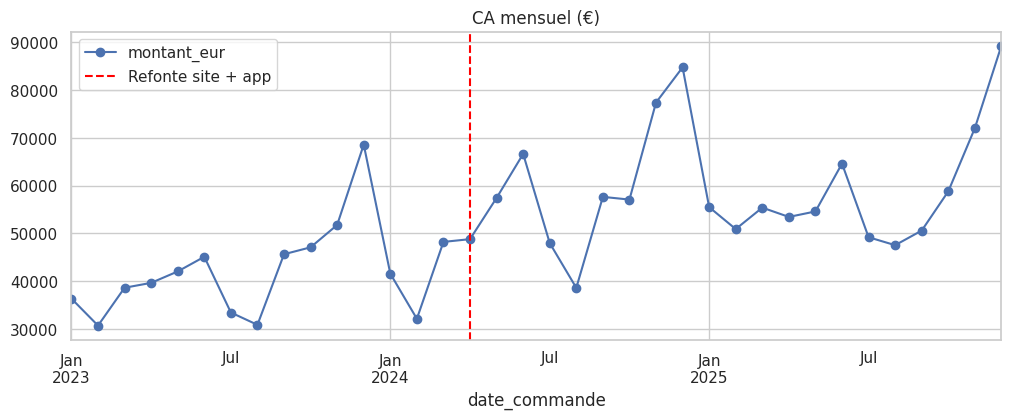

annee,2023,2024,2025
mois,,,
1,36354.0,41579.0,55495.0
2,30710.0,32134.0,50907.0
3,38628.0,48222.0,55394.0
4,39653.0,48800.0,53450.0
5,42042.0,57430.0,54598.0
6,45108.0,66635.0,64608.0
7,33446.0,47974.0,49199.0
8,30866.0,38603.0,47538.0
9,45643.0,57649.0,50595.0


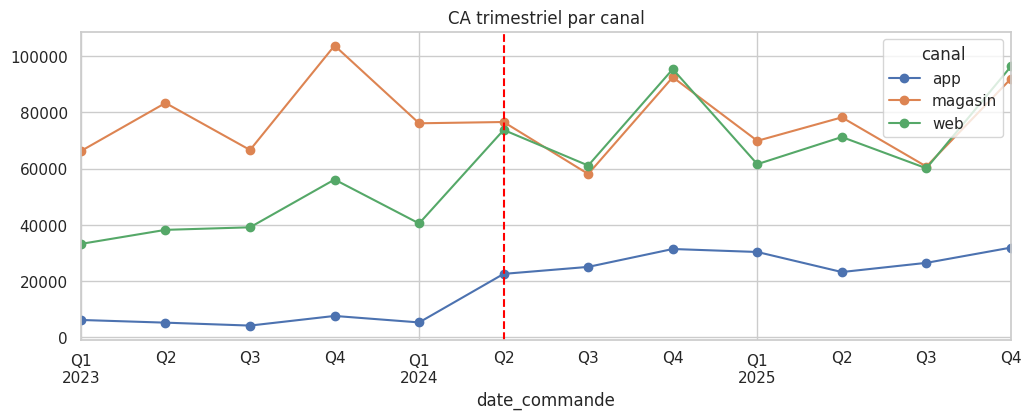

Durées en mois : {'avant': 15.4, 'après': 20.5}


,cmd/mois avant,cmd/mois après,CA/mois avant,CA/mois après,évol. CA %
canal,,,,,
app,25.0,113.0,1911.0,9269.0,385.0
magasin,352.0,323.0,26493.0,25067.0,-5.0
web,179.0,320.0,13783.0,25020.0,82.0


CA mensuel total : 42187 € avant → 59356 € après (+41 %)


In [18]:
# CA mensuel
mensuel = df.set_index("date_commande").resample("MS")["montant_eur"].sum()
plt.figure(figsize=(12, 4))
mensuel.plot(marker="o")
plt.axvline(REFONTE, color="red", linestyle="--", label="Refonte site + app")
plt.title("CA mensuel (€)"); plt.legend(); plt.show()

# Saisonnalité
display(df.pivot_table(index="mois", columns="annee", values="montant_eur", aggfunc="sum").round(0))

# CA trimestriel par canal
par_canal = df.groupby([pd.Grouper(key="date_commande", freq="QS"), "canal"])["montant_eur"].sum().unstack()
par_canal.plot(figsize=(12, 4), marker="o", title="CA trimestriel par canal")
plt.axvline(REFONTE, color="red", linestyle="--"); plt.show()

# Avant / après refonte, RAMENÉ PAR MOIS (les deux périodes n'ont pas la même durée)
df["periode"] = np.where(df["date_commande"] < REFONTE, "avant", "après")
debut, fin = df["date_commande"].min(), df["date_commande"].max()
nb_mois = {"avant": (REFONTE - debut).days / 30.44, "après": (fin - REFONTE).days / 30.44}
print("Durées en mois :", {k: round(v, 1) for k, v in nb_mois.items()})

cmd = df.groupby(["canal", "periode"]).size().unstack()
ca = df.groupby(["canal", "periode"])["montant_eur"].sum().unstack()
res = pd.DataFrame({
    "cmd/mois avant": cmd["avant"] / nb_mois["avant"],
    "cmd/mois après": cmd["après"] / nb_mois["après"],
    "CA/mois avant": ca["avant"] / nb_mois["avant"],
    "CA/mois après": ca["après"] / nb_mois["après"],
}).round(0)
res["évol. CA %"] = ((res["CA/mois après"] / res["CA/mois avant"] - 1) * 100).round(0)
display(res)
tot_avant, tot_apres = res["CA/mois avant"].sum(), res["CA/mois après"].sum()
print(f"CA mensuel total : {tot_avant:.0f} € avant → {tot_apres:.0f} € après ({(tot_apres/tot_avant-1)*100:+.0f} %)")

In [19]:
for col in ["canal", "categorie", "tranche_age", "region", "genre"]:
    t = df.groupby(col)["montant_eur"].agg(commandes="count", ca="sum", panier_moyen="mean").round(1)
    t["part_ca_%"] = (t["ca"] / t["ca"].sum() * 100).round(1)
    t["part_cmd_%"] = (t["commandes"] / t["commandes"].sum() * 100).round(1)
    print(f"\n--- {col} ---")
    display(t.sort_values("ca", ascending=False))

display(df.pivot_table(index="categorie", columns="annee", values="montant_eur", aggfunc="sum").round(0))


--- canal ---


,commandes,ca,panier_moyen,part_ca_%,part_cmd_%
canal,,,,,
magasin,12069,923737.5,76.5,49.4,50.1
web,9328,726519.7,77.9,38.8,38.7
app,2706,219821.0,81.2,11.8,11.2



--- categorie ---


,commandes,ca,panier_moyen,part_ca_%,part_cmd_%
categorie,,,,,
Mobilier,1957,652854.6,333.6,34.9,8.1
Luminaire,4829,425043.7,88.0,22.7,20.0
Textile,6567,308834.5,47.0,16.5,27.2
Déco,7167,279629.5,39.0,15.0,29.7
Cuisine,3583,203716.0,56.9,10.9,14.9



--- tranche_age ---


,commandes,ca,panier_moyen,part_ca_%,part_cmd_%
tranche_age,,,,,
25-34,7126,540171.0,75.8,28.9,29.6
35-44,5960,472362.6,79.3,25.3,24.7
45-54,4113,317933.1,77.3,17.0,17.1
18-24,3396,265062.3,78.1,14.2,14.1
55-64,2042,162780.1,79.7,8.7,8.5
65+,1466,111769.1,76.2,6.0,6.1



--- region ---


,commandes,ca,panier_moyen,part_ca_%,part_cmd_%
region,,,,,
Île-de-France,7574,575126.8,75.9,31.0,31.7
Sud-Est,4851,383708.4,79.1,20.7,20.3
Ouest,4294,337946.7,78.7,18.2,18.0
Nord-Est,4011,314422.8,78.4,17.0,16.8
Sud-Ouest,2782,214526.2,77.1,11.6,11.7
Outre-mer,353,26910.5,76.2,1.5,1.5



--- genre ---


,commandes,ca,panier_moyen,part_ca_%,part_cmd_%
genre,,,,,
F,15116,1166868.8,77.2,62.4,62.7
H,8987,703209.4,78.2,37.6,37.3


annee,2023,2024,2025
categorie,,,
Cuisine,57095.0,71965.0,74656.0
Déco,76678.0,92657.0,110295.0
Luminaire,112689.0,150938.0,161417.0
Mobilier,180683.0,233828.0,238344.0
Textile,82757.0,108850.0,117227.0



% de commandes avec offre, par tranche_age :


,offre_personnalisee
tranche_age,
18-24,47.8
25-34,48.4
35-44,38.5
45-54,40.2
55-64,24.8
65+,17.4



% de commandes avec offre, par genre :


,offre_personnalisee
genre,
F,42.1
H,38.1



% de commandes avec offre, par region :


,offre_personnalisee
region,
Nord-Est,40.3
Ouest,40.6
Outre-mer,25.5
Sud-Est,40.5
Sud-Ouest,41.2
Île-de-France,41.4


... (2 outputs left out)


% de commandes avec offre, par carte_fidelite :


,offre_personnalisee
carte_fidelite,
0,39.2
1,42.1



% avec offre, par tranche d'âge ET canal :


canal,app,magasin,web
tranche_age,,,
18-24,51.8,46.0,48.7
25-34,52.1,44.9,51.3
35-44,42.5,35.1,41.2
45-54,44.4,35.4,44.3
55-64,34.8,22.5,28.4
65+,24.2,13.8,26.4


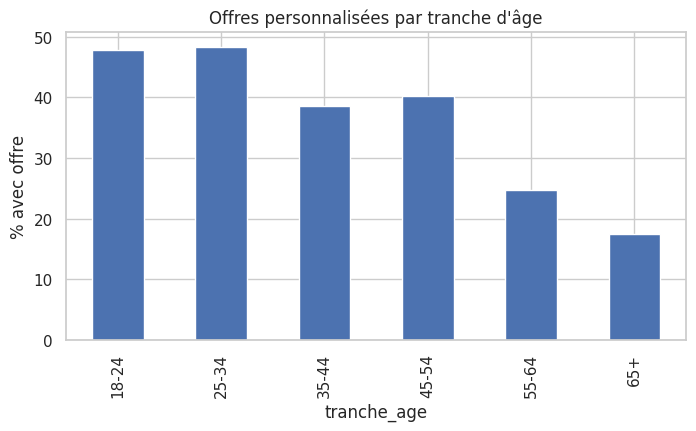

,rachat_90j,montant_eur,remise_pct
offre_personnalisee,,,
0,0.342,78.367,5.226
1,0.442,76.445,5.293


In [20]:
for col in ["tranche_age", "genre", "region", "canal", "carte_fidelite"]:
    print(f"\n% de commandes avec offre, par {col} :")
    display((df.groupby(col)["offre_personnalisee"].mean() * 100).round(1))

# Contrôle clé : l'écart par âge persiste-t-il À CANAL CONSTANT ?
print("\n% avec offre, par tranche d'âge ET canal :")
display((df.pivot_table(index="tranche_age", columns="canal",
                        values="offre_personnalisee", aggfunc="mean") * 100).round(1))

(df.groupby("tranche_age")["offre_personnalisee"].mean() * 100).plot(kind="bar", figsize=(8, 4))
plt.ylabel("% avec offre"); plt.title("Offres personnalisées par tranche d'âge"); plt.show()

# Les offres sont-elles associées à plus de rachats ?
display(df.groupby("offre_personnalisee")[["rachat_90j", "montant_eur", "remise_pct"]].mean().round(3))


--- tranche_age ---


,clientèle_%,population_%,écart_pts,ratio
65+,6.2,26.0,-19.8,0.24
55-64,8.7,16.0,-7.3,0.54
45-54,16.4,17.0,-0.6,0.96
18-24,13.9,10.0,3.9,1.39
35-44,25.3,16.0,9.3,1.58
25-34,29.5,15.0,14.5,1.97



--- genre ---


,clientèle_%,population_%,écart_pts,ratio
H,37.6,48.0,-10.4,0.78
F,62.4,52.0,10.4,1.20



--- region ---


,clientèle_%,population_%,écart_pts,ratio
Nord-Est,17.0,24.0,-7.0,0.71
Ouest,17.6,21.0,-3.4,0.84
Sud-Ouest,11.7,14.0,-2.3,0.84
Outre-mer,1.5,3.0,-1.5,0.50
Sud-Est,20.9,19.0,1.9,1.10
Île-de-France,31.3,19.0,12.3,1.65


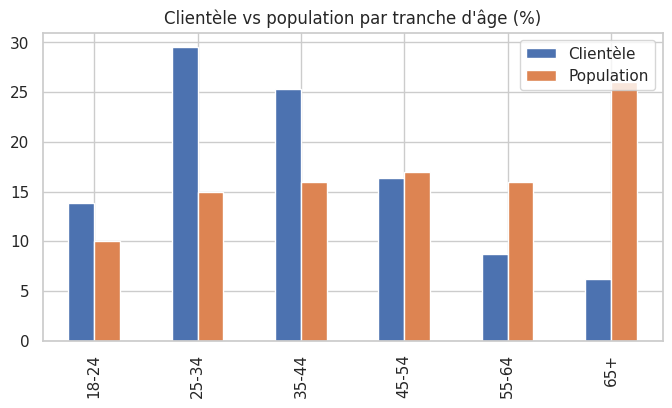

In [21]:
clients = df.sort_values("date_commande").drop_duplicates("client_id")
ref = reference()

for var in ["tranche_age", "genre", "region"]:
    r = ref[ref["variable"] == var].set_index("modalite")["part_reference"] * 100
    c = clients[var].value_counts(normalize=True) * 100
    t = pd.DataFrame({"clientèle_%": c.round(1), "population_%": r}).dropna()
    t["écart_pts"] = (t["clientèle_%"] - t["population_%"]).round(1)
    t["ratio"] = (t["clientèle_%"] / t["population_%"]).round(2)
    print(f"\n--- {var} ---")
    display(t.sort_values("écart_pts"))

t = pd.DataFrame({
    "Clientèle": clients["tranche_age"].value_counts(normalize=True) * 100,
    "Population": ref[ref["variable"] == "tranche_age"].set_index("modalite")["part_reference"] * 100
}).sort_index()
t.plot(kind="bar", figsize=(8, 4), title="Clientèle vs population par tranche d'âge (%)")
plt.show()

## Vos réponses

**1. Une ligne =** une commande (un `commande_id`) passée par un client identifié (`client_id`), sur un canal (magasin, web, app) et dans une catégorie de produits. Ce n'est pas une ligne par article.

**2. Période et volumes :** du 1er janvier 2023 au 31 décembre 2025 (3 ans). 24 224 lignes brutes, dont 121 doublons exacts supprimés, soit 24 103 commandes, 6 768 clients et 3,56 commandes par client. CA net (avoirs inclus) : 1,87 M€, soit 510 k€ en 2023, 658 k€ en 2024 (+29 %) et 702 k€ en 2025 (+7 %).

**3. Variables clés pour Camille Roux :**
- `montant_eur`, `date_commande` : CA, saisonnalité (pic en décembre), effet de la refonte du 15/04/2024.
- `canal` : magasin ≈ 49 % du CA, web ≈ 39 %, app ≈ 12 %.
- `categorie` : le Mobilier fait ≈ 35 % du CA avec ≈ 8 % des commandes (panier moyen ≈ 334 €).
- `tranche_age`, `genre`, `region` : profils clients et représentativité.
- `offre_personnalisee`, `rachat_90j` : équité et efficacité de l'algorithme.

**4. Problèmes de qualité :**
- 121 doublons exacts (0,5 %), supprimés.
- `note_satisfaction` manquante à 55 % : note facultative, donc échantillon biaisé.
- `region` manquante sur 241 lignes (1 %).
- 15 avoirs (montants négatifs, jusqu'à -128 €) : pas une erreur, je les garde pour le CA net.
- Commande extrême à 5 407 € (médiane ≈ 49 €), à vérifier.
- Des commandes `app` existent dès le 01/01/2023, soit environ 390 avant le « lancement » du 15/04/2024 : incohérence avec le brief à signaler.
- Âge et tranche d'âge cohérents, pas de catégories mal écrites, pas de dates hors période.

**5. Hypothèses :**
- **H1 (refonte) :** elle a déplacé l'activité vers le digital. Par mois, le web passe de 179 à 320 commandes (CA +82 %), l'app de 25 à 113 (CA +385 %, depuis un niveau très bas), le magasin de 352 à 323 (CA -5 %). Le CA mensuel total gagne ≈ 41 %, mais la croissance se tasse (+29 % puis +7 %). La saisonnalité et la tendance de fond brouillent l'effet : à tester.
- **H2 (équité) :** l'algorithme sous-cible les seniors. Les 65+ reçoivent une offre dans ≈ 17 % des cas contre ≈ 48 % pour les 25-34 ans, et l'écart persiste dans chaque canal (65+ : 14 % magasin, 24 % app, 26 % web ; 25-34 : 45 % magasin, 52 % app, 51 % web). Les clients avec offre rachètent plus (≈ 44 % contre 34 %), mais corrélation ne prouve pas causalité.
- **H3 (représentativité) :** la clientèle sous-représente les seniors : 65+ = 6 % des clients contre 26 % de la population, 55-64 = 9 % contre 16 %. Les 25-44 ans (55 % contre 31 %), l'Île-de-France (31 % contre 19 %) et les femmes (62 % contre 52 %) sont sur-représentés.